# Exploratory Data Analysis

**Retail Store Inventory Demand Forecasting** (AAI-540, Group 4)

Dataset: [Kaggle Retail Store Inventory Forecasting Dataset](https://www.kaggle.com/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset) — 73,100 daily records, 5 stores × 20 products, 2022-01-01 to 2024-01-01. The dataset is synthetic.

This notebook profiles the raw data, checks data quality, and visualizes the patterns that motivate the feature engineering and modeling choices in `src/`.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_ingestion.data_ingestion import load_data, validate_schema, TARGET_COLUMN

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)

In [2]:
df = load_data('../data/raw/retail_store_inventory.csv')
print(df.shape)
df.head()

(73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


## Schema and data-quality report

`validate_schema` checks column presence/types, nulls, negative targets and duplicate (date, store, product) keys, and returns a small report that the training pipeline also logs to MLflow.

In [3]:
report = validate_schema(df)
report

{'n_rows': 73100,
 'n_stores': 5,
 'n_products': 20,
 'date_min': '2022-01-01',
 'date_max': '2024-01-01',
 'n_duplicate_keys': 0,
 'target_mean': 136.46,
 'target_zero_rate': 0.0049}

In [4]:
df.dtypes

Date                  datetime64[us]
Store ID                         str
Product ID                       str
Category                         str
Region                           str
Inventory Level                int64
Units Sold                     int64
Units Ordered                  int64
Demand Forecast              float64
Price                        float64
Discount                       int64
Weather Condition                str
Holiday/Promotion              int64
Competitor Pricing           float64
Seasonality                      str
dtype: object

In [5]:
df.describe()

,Date,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,2023-01-01 00:00:00,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
min,2022-01-01 00:00:00,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,2022-07-02 00:00:00,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,2023-01-01 00:00:00,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,2023-07-03 00:00:00,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,2024-01-01 00:00:00,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000
std,NaN,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408


## Categorical frequencies

The dataset is perfectly balanced across stores (5) and near-balanced across products (20), categories, regions, weather and seasonality — consistent with it being synthetically generated rather than observed.

In [6]:
for col in ['Store ID', 'Category', 'Region', 'Weather Condition', 'Seasonality', 'Holiday/Promotion']:
    print(f"\n{col}:")
    print(df[col].value_counts())


Store ID:
Store ID
S001    14620
S002    14620
S003    14620
S004    14620
S005    14620
Name: count, dtype: int64

Category:
Category
Furniture      14699
Toys           14643
Clothing       14626
Groceries      14611
Electronics    14521
Name: count, dtype: int64

Region:
Region
East     18349
South    18297
North    18228
West     18226
Name: count, dtype: int64

Weather Condition:
Weather Condition
Sunny     18290
Rainy     18278
Snowy     18272
Cloudy    18260
Name: count, dtype: int64

Seasonality:
Seasonality
Spring    18317
Summer    18305
Winter    18285
Autumn    18193
Name: count, dtype: int64

Holiday/Promotion:
Holiday/Promotion
0    36747
1    36353
Name: count, dtype: int64


## Target distribution

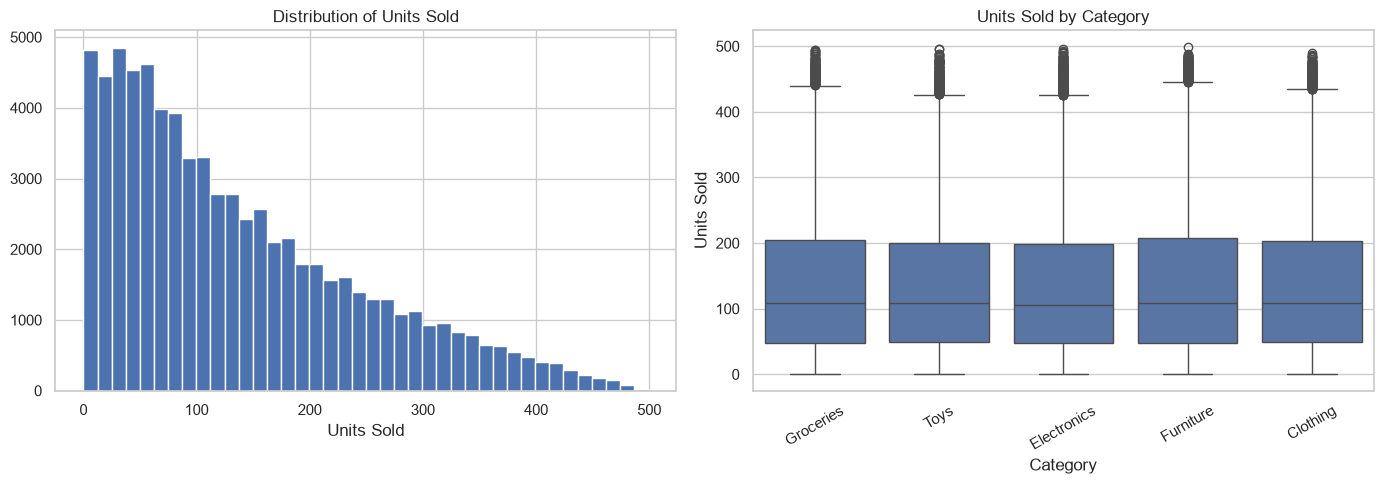

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df[TARGET_COLUMN], bins=40)
axes[0].set_title('Distribution of Units Sold')
axes[0].set_xlabel('Units Sold')

sns.boxplot(x='Category', y=TARGET_COLUMN, data=df, ax=axes[1])
axes[1].set_title('Units Sold by Category')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## Time series patterns

Aggregate daily sales across all stores/products to inspect trend, weekly seasonality and any visible drift over the two-year window.

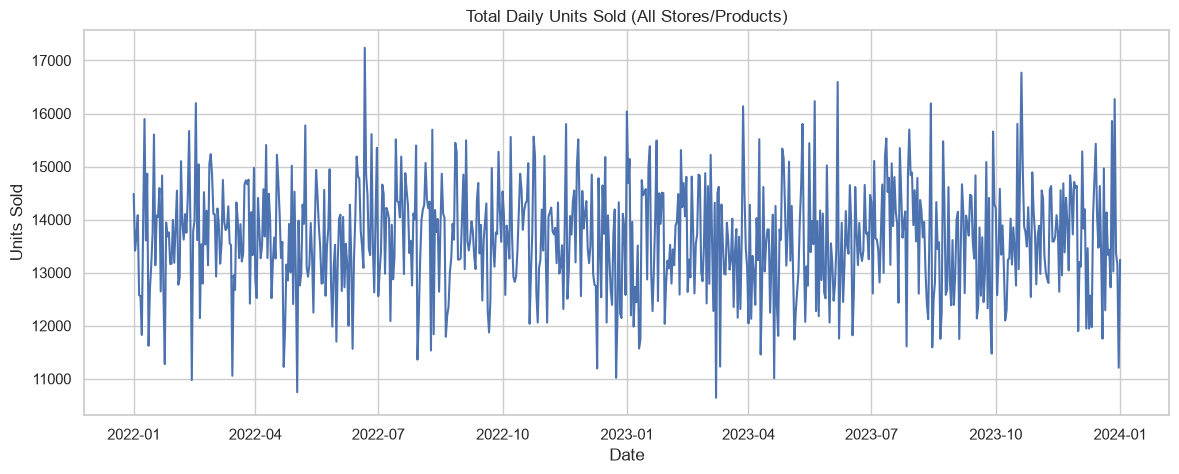

In [8]:
daily_sales = df.groupby('Date')[TARGET_COLUMN].sum().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales['Date'], daily_sales[TARGET_COLUMN])
plt.title('Total Daily Units Sold (All Stores/Products)')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.show()

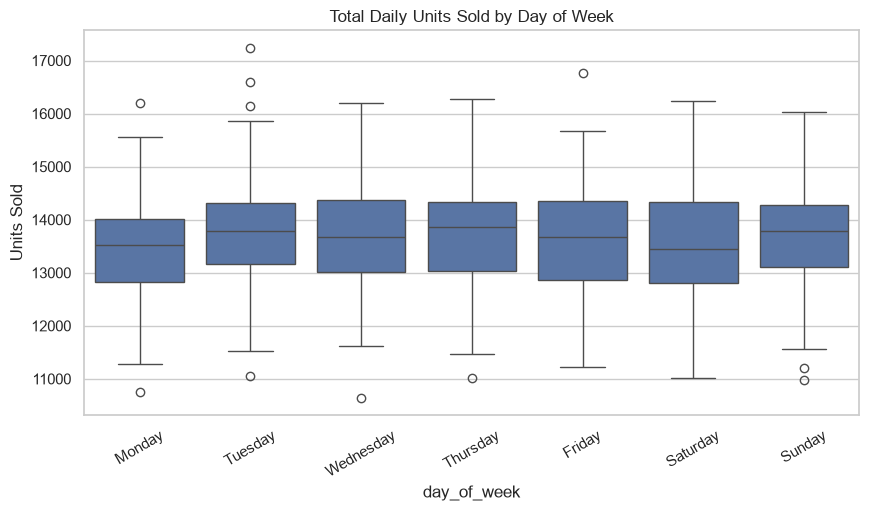

In [9]:
daily_sales['day_of_week'] = daily_sales['Date'].dt.day_name()
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(10, 5))
sns.boxplot(x='day_of_week', y=TARGET_COLUMN, data=daily_sales, order=order)
plt.title('Total Daily Units Sold by Day of Week')
plt.xticks(rotation=30)
plt.show()

## Holiday/promotion effect

In [10]:
promo_effect = df.groupby('Holiday/Promotion')[TARGET_COLUMN].agg(['mean', 'median', 'count'])
promo_effect

,mean,median,count
Holiday/Promotion,,,
0,136.505375,107.0,36747
1,136.423926,108.0,36353


## Correlation between numeric columns

`Demand Forecast` correlates strongly with `Units Sold` because it is the dataset's own pre-computed forecast; it is excluded from model features (see `config.yaml: data.excluded_features`) since using it as an input would leak a forecast of the target.

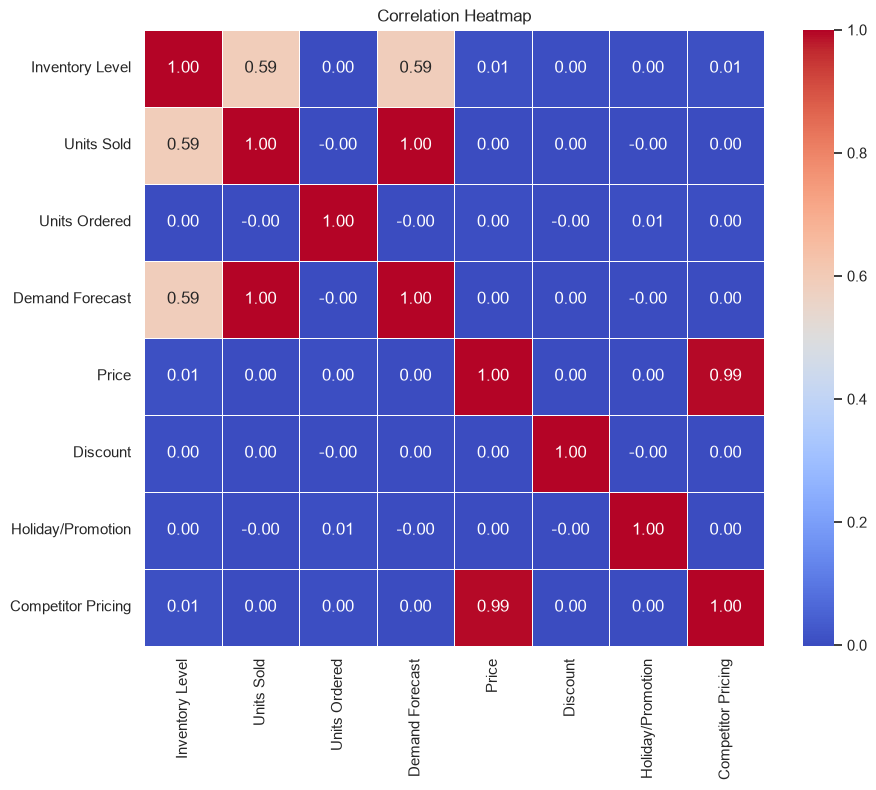

In [11]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

## Key observations

- No missing values; no duplicate (Date, Store ID, Product ID) keys.
- Stores and products are evenly represented — consistent with a synthetically generated dataset rather than organically observed retail data.
- `Units Sold` is right-skewed with no strong weekly seasonality pattern visible in the boxplot by day-of-week (unlike many real retail datasets), which limits how much a seasonal-naive or calendar-feature-driven model can improve on pure noise.
- `Demand Forecast` is highly correlated with `Units Sold` by construction and must be excluded as a feature to avoid leakage.
- `Inventory Level` and `Units Ordered` are partly determined by `Units Sold` after the fact and are also excluded as pre-contact/pre-period features would not be available at forecast time.
- Given the weak and largely synthetic signal, we expect WAPE to stay well above zero even for the best model; see `model_evaluation.ipynb` for the actual numbers and the seasonal-naive baseline comparison that quantifies how much (if any) the learned models add.